# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [1]:
# run this first if you dont have them installed in your env
!pip install pandas numpy matplotlib scipy


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)
rng = np.random.default_rng(42)  # use rng for all random sampling so your results are reproducible

df = pd.read_csv("../data/cars.csv")
print(df.shape)
df.head()

(11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [3]:
# Explore here. Add as many cells as you need.
# Useful: .duplicated(), .value_counts(), .describe(), .isna().sum(), .nlargest(), .groupby(...).nunique()

# let's check duplicates
df.duplicated().sum()

np.int64(720)

In [4]:
# lets use info to get a quick overview of the dataset 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  str    
 1   Model              11914 non-null  str    
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  str    
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  str    
 7   Driven_Wheels      11914 non-null  str    
 8   Number of Doors    11908 non-null  float64
 9   Vehicle Size       11914 non-null  str    
 10  Vehicle Style      11914 non-null  str    
 11  highway MPG        11914 non-null  int64  
 12  city mpg           11914 non-null  int64  
 13  Popularity         11914 non-null  int64  
 14  MSRP               11914 non-null  int64  
dtypes: float64(3), int64(5), str(7)
memory usage: 1.4 MB


In [5]:
# check for missing values 
df.isna().sum()

Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           0
city mpg              0
Popularity            0
MSRP                  0
dtype: int64

In [10]:
# check groups of cetegorical features and their unique values
# print unique values and counts of each group
cat_features = df.select_dtypes(include='object').columns

for col in cat_features: 
  print(f"Column: {col}")
  print(f"Unique values: {df[col].nunique()}")
  print(f"Unique groups: {df[col].value_counts()}")
  print("\n")


Column: Make
Unique values: 48
Unique groups: Make
Chevrolet        1123
Ford              881
Volkswagen        809
Toyota            746
Dodge             626
Nissan            558
GMC               515
Honda             449
Mazda             423
Cadillac          397
Mercedes-Benz     353
Suzuki            351
BMW               334
Infiniti          330
Audi              328
Hyundai           303
Volvo             281
Subaru            256
Acura             252
Kia               231
Mitsubishi        213
Lexus             202
Buick             196
Chrysler          187
Pontiac           186
Lincoln           164
Oldsmobile        150
Land Rover        143
Porsche           136
Saab              111
Aston Martin       93
Plymouth           82
Bentley            74
Ferrari            69
FIAT               62
Scion              60
Maserati           58
Lamborghini        52
Rolls-Royce        31
Lotus              29
Tesla              18
HUMMER             17
Maybach            16
Alf

/var/folders/b4/mzx1tj753sdgm4pjdk68j9gr0000gn/T/ipykernel_53827/1057643133.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = df.select_dtypes(include='object').columns


In [16]:
# Check large values of numerical features
num_features = df.select_dtypes(include='number').columns 

# for each col, print 5 largest values and their corresponding rows 
for col in num_features:
  print(f"Column: {col}")
  print(f"5 largest value: \n{df[col].nlargest(5)}")
  print("\n")

Column: Year
5 largest value: 
32    2017
33    2017
34    2017
50    2017
51    2017
Name: Year, dtype: int64


Column: Engine HP
5 largest value: 
11362    1001.0
11363    1001.0
11364    1001.0
1629      750.0
1630      750.0
Name: Engine HP, dtype: float64


Column: Engine Cylinders
5 largest value: 
11362    16.0
11363    16.0
11364    16.0
460      12.0
461      12.0
Name: Engine Cylinders, dtype: float64


Column: Number of Doors
5 largest value: 
17    4.0
18    4.0
19    4.0
20    4.0
21    4.0
Name: Number of Doors, dtype: float64


Column: highway MPG
5 largest value: 
1119    354
5790    111
5791    111
5792    111
1983    110
Name: highway MPG, dtype: int64


Column: city mpg
5 largest value: 
5790    137
5791    137
5792    137
4705    132
4706    132
Name: city mpg, dtype: int64


Column: Popularity
5 largest value: 
1331    5657
1332    5657
1333    5657
1334    5657
1335    5657
Name: Popularity, dtype: int64


Column: MSRP
5 largest value: 
11362    2065902
11364    1

In [ ]:
df.iloc[1119] # highway MPG is unusually high (354)

Make                                           Audi
Model                                            A6
Year                                           2017
Engine Fuel Type     premium unleaded (recommended)
Engine HP                                     252.0
Engine Cylinders                                4.0
Transmission Type                  AUTOMATED_MANUAL
Driven_Wheels                     front wheel drive
Number of Doors                                 4.0
Vehicle Size                                Midsize
Vehicle Style                                 Sedan
highway MPG                                     354
city mpg                                         24
Popularity                                     3105
MSRP                                          51600
Name: 1119, dtype: object

In [25]:
# lets inspect rows that have MSRP = 2000 
df[df["MSRP"] == 2000].head(10)

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
17,Audi,100,1992,regular unleaded,172.0,6.0,MANUAL,front wheel drive,4.0,Midsize,Sedan,24,17,3105,2000
18,Audi,100,1992,regular unleaded,172.0,6.0,MANUAL,front wheel drive,4.0,Midsize,Sedan,24,17,3105,2000
19,Audi,100,1992,regular unleaded,172.0,6.0,AUTOMATIC,all wheel drive,4.0,Midsize,Wagon,20,16,3105,2000
20,Audi,100,1992,regular unleaded,172.0,6.0,MANUAL,front wheel drive,4.0,Midsize,Sedan,24,17,3105,2000
21,Audi,100,1992,regular unleaded,172.0,6.0,MANUAL,all wheel drive,4.0,Midsize,Sedan,21,16,3105,2000
22,Audi,100,1993,regular unleaded,172.0,6.0,MANUAL,front wheel drive,4.0,Midsize,Sedan,24,17,3105,2000
23,Audi,100,1993,regular unleaded,172.0,6.0,AUTOMATIC,all wheel drive,4.0,Midsize,Wagon,20,16,3105,2000
24,Audi,100,1993,regular unleaded,172.0,6.0,MANUAL,front wheel drive,4.0,Midsize,Sedan,24,17,3105,2000
25,Audi,100,1993,regular unleaded,172.0,6.0,MANUAL,front wheel drive,4.0,Midsize,Sedan,24,17,3105,2000
26,Audi,100,1993,regular unleaded,172.0,6.0,MANUAL,all wheel drive,4.0,Midsize,Sedan,21,16,3105,2000


**Cleaning log:** fill in one row per problem.

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---:|---|---|
| 1 | Exact duplicate rows | `df.duplicated().sum()` | 720 | Dropped duplicate rows | Duplicate observations could unfairly influence summary statistics and tests. |
| 2 | Missing values in fuel type, horsepower, cylinders, and doors | `df.isna().sum()` | 102 rows | Left as NaN and excluded them only from analyses requiring those fields | Dropping entire rows would discard other valid information. Some missing cylinders are structurally reasonable for electric or rotary engines. |
| 3 | `UNKNOWN` transmission type | `value_counts()` on categorical columns | 19 | Replaced `UNKNOWN` with NaN | `UNKNOWN` represents missing information, not a real transmission type. |
| 4 | Suspicious highway MPG value of 354 for a gasoline Audi A6 | `df.nlargest(5, "highway MPG")` | 1 | Replaced the value with NaN | The value is inconsistent with the car and likely a data-entry error; guessing the correction would be unsafe. |
| 5 | MSRP of exactly $2,000 appears unusually often | `df["MSRP"].value_counts()` | 1,036 | Replaced $2,000 values with NaN | The repeated minimum appears to be a placeholder rather than a trustworthy MSRP. |

In [27]:
# Build your cleaned DataFrame. Start from a copy so df stays untouched.
clean = df.copy()
clean.columns = clean.columns.str.strip().str.lower().str.replace(" ", "_")  # freebie: snake_case names

In [ ]:
# Let's apply the methods mentioned in the cleaning log

# 1. Remove exact duplicate observations.
clean = clean.drop_duplicates()

# 2. Keep the existing missing values so valid information in those rows is retained.

# 3. Treat UNKNOWN as missing because it is not a transmission category.
clean["transmission_type"] = clean["transmission_type"].replace("UNKNOWN", np.nan)

# 4. Remove the implausible MPG value without dropping the rest of the Audi A6 row.
clean.loc[clean["highway_mpg"] == 354, "highway_mpg"] = np.nan

# 5. Treat the repeated $2,000 MSRP placeholder as missing while retaining each vehicle row.
clean.loc[clean["msrp"] == 2000, "msrp"] = np.nan

In [ ]:
# Checkpoint: run this before moving on.
print(clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
# Fewer than ~10,000 rows? You probably dropped too much. Go back and use NaN or a flag instead.

(11914, 15)
engine_fuel_type     3
engine_hp           69
engine_cylinders    30
number_of_doors      6
dtype: int64


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?

Mean: 40594.737032063116, Median: 29995.0


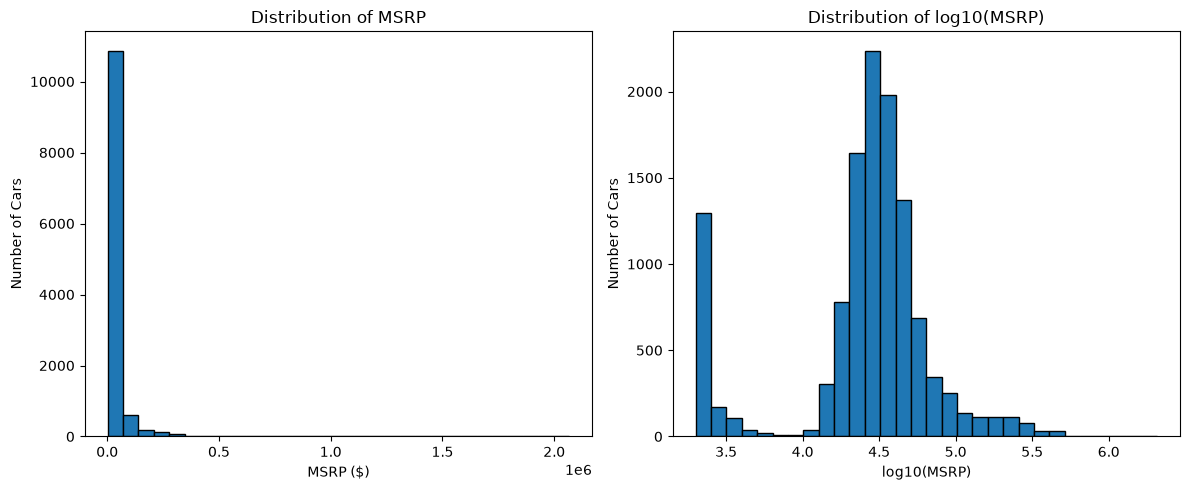

Share of cars above the mean: 27.44%

I would use the median MSRP as the typical price. Only 27% of cars cost more than the mean, showing that a small number of expensive cars pull the mean upward. The median better represents the price a typical customer would encounter.


In [34]:
# a) mean and median
mean = clean["msrp"].mean()
median = clean["msrp"].median()
print(f"Mean: {mean}, Median: {median}")

# b) two histograms side by side
msrp = clean["msrp"].dropna() # drop NaN values for plotting 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(msrp, bins=30, edgecolor="black")
axes[0].set_title("Distribution of MSRP")
axes[0].set_xlabel("MSRP ($)")
axes[0].set_ylabel("Number of Cars")

# The original MSRP distribution is strongly right-skewed because a small number of very expensive cars stretch the scale. Applying log10 reduces this skew and makes the distribution of most car prices easier to see.
axes[1].hist(np.log10(msrp), bins=30, edgecolor="black")
axes[1].set_title("Distribution of log10(MSRP)")
axes[1].set_xlabel("log10(MSRP)")
axes[1].set_ylabel("Number of Cars")

plt.tight_layout()
plt.show()

# c) share of cars above the mean
above_mean = clean["msrp"].dropna() > mean
share_above_mean = above_mean.sum() / len(clean["msrp"].dropna()) # get the percentage of cars above the mean
print(f"Share of cars above the mean: {share_above_mean:.2%}\n")

# d) Which figure belows on the homepage
print("I would use the median MSRP as the typical price. Only 27% of cars cost more than the mean, showing that a small number of expensive cars pull the mean upward. The median better represents the price a typical customer would encounter.")

**Answer:**

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [41]:
# a) mean and std of highway_mpg by vehicle_size, 2017 only
mean = clean[clean["year"] == 2017].groupby("vehicle_size")["highway_mpg"].mean() 
std = clean[clean["year"] == 2017].groupby("vehicle_size")["highway_mpg"].std()

# b) z = (value - class mean) / class std
civic_z = (42 - mean["Compact"]) / std["Compact"]
volvo_z = (34 - mean["Large"]) / std["Large"]
  
# c) z-score map 
z_scores = {
  "Honda Civic": civic_z,
  "Volvo s90": volvo_z  
}
print("Z-scores for 2017 models: \n", z_scores)
print("\n")
# c) Which car is more unusual?
print("The Honda Civic’s highway MPG is 0.95 standard deviations above the Compact-class mean, while the Volvo S90’s is 3.16 standard deviations above the Large-class mean. Therefore, the Volvo S90 is substantially more fuel-efficient for its class and is the more unusual performer.")

Z-scores for 2017 models: 
 {'Honda Civic': np.float64(0.9504128052192553), 'Volvo s90': np.float64(3.1572046787829264)}


The Honda Civic’s highway MPG is 0.95 standard deviations above the Compact-class mean, while the Volvo S90’s is 3.16 standard deviations above the Large-class mean. Therefore, the Volvo S90 is substantially more fuel-efficient for its class and is the more unusual performer.


**Answer:**

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

In [50]:
def bootstrap_median(values, n_boot=5000):
    """Return an array of n_boot bootstrap medians."""
    # hint: rng.choice(values, size=len(values), replace=True)
    rng = np.random.default_rng(42) # use rng for all random sampling so your results are reproducible
    bootstrap_medians = []

    for _ in range(n_boot):
        bootstrap_sample = rng.choice(
            values, 
            size=len(values),
            replace=True # with replacement to allow for duplicates in the sample
        )
        bootstrap_medians.append(np.median(bootstrap_sample))

    return np.array(bootstrap_medians)

# a, b)
prices_2017 = clean.loc[clean["year"] == 2017, "msrp"].dropna() 

actual_median = prices_2017.median()
boot_medians = bootstrap_median(prices_2017)

confidence_interval = np.percentile(boot_medians, [2.5, 97.5]) # returns the 2.5th and 97.5th percentiles of the bootstrap medians, which gives us the 95% confidence interval

print("Median MSRP:", actual_median)
print("95% bootstrap interval:", confidence_interval)

# c)
cars_2017 = clean[clean["year"] == 2017]

make_counts = cars_2017.groupby("make").size()
eligible_makes = make_counts[make_counts < 50]

print(eligible_makes)

# Lets choose Volvo
chosen_make = "Volvo"

make_prices = cars_2017.loc[
    cars_2017["make"] == chosen_make, "msrp"
].dropna()

make_boot_medians = bootstrap_median(make_prices)
make_ci = np.percentile(make_boot_medians, [2.5, 97.5])

print("\nMake:", chosen_make)
print("Number of cars:", len(make_prices))
print("Median MSRP:", make_prices.median())
print("95% interval:", make_ci)

# explain interval from b
print(
    f"\nBased on the available data, the typical price of a 2017 car "
    f"is likely between ${confidence_interval[0]:,.0f} "
    f"and ${confidence_interval[1]:,.0f}."
)


Median MSRP: 36647.5
95% bootstrap interval: [35870. 37650.]
make
Acura         36
Buick         39
Chrysler      24
FIAT          19
Genesis        3
Infiniti      28
Kia           43
Land Rover    11
Lexus         34
Lincoln       46
Lotus          2
Maserati      13
Mazda         24
Mitsubishi    29
Porsche       25
Subaru        47
Volvo         25
dtype: int64

Make: Volvo
Number of cars: 25
Median MSRP: 46350.0
95% interval: [41700. 50450.]

Based on the available data, the typical price of a 2017 car is likely between $35,870 and $37,650.


**Answer:**

---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

Number of rows: 534
Mean MPG: 31.833333333333332
Median MPG: 30.0


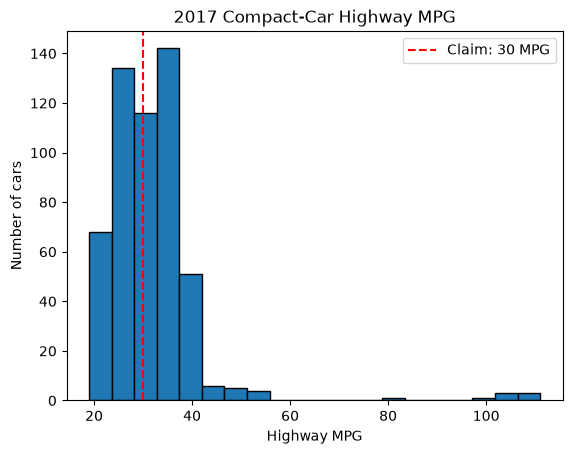

Row-level t-statistic: 3.960461152531368
Row-level p-value: 4.2483534841036124e-05

Rows per model:
make           model                 
Toyota         Tacoma                    32
Chevrolet      Corvette                  24
Nissan         Frontier                  22
               370Z                      17
Ford           Transit Connect           16
                                         ..
               Focus RS                   1
FIAT           500e                       1
Mitsubishi     i-MiEV                     1
Mercedes-Benz  B-Class Electric Drive     1
Ford           Focus ST                   1
Length: 90, dtype: int64

Number of unique models: 90

Model-level sample size: 90
Model-level mean MPG: 35.624468863562
Model-level t-statistic: 3.096200618564181
Model-level p-value: 0.0013106660623769784


In [52]:
# b) Sample: 2017 compact cars with valid highway MPG
compact_2017 = clean.loc[
    (clean["year"] == 2017) &
    (clean["vehicle_size"] == "Compact"),
    "highway_mpg"
].dropna()

print("Number of rows:", len(compact_2017))
print("Mean MPG:", compact_2017.mean())
print("Median MPG:", compact_2017.median())

plt.hist(compact_2017, bins=20, edgecolor="black")
plt.axvline(30, color="red", linestyle="--", label="Claim: 30 MPG") # vertical line at 30 MPG to indicate the claim 
plt.xlabel("Highway MPG")
plt.ylabel("Number of cars")
plt.title("2017 Compact-Car Highway MPG")
plt.legend()
plt.show()


# c) One-sample, one-sided t-test
row_test = stats.ttest_1samp(
    compact_2017,
    popmean=30,
    alternative="greater"
)

print("Row-level t-statistic:", row_test.statistic)
print("Row-level p-value:", row_test.pvalue)


# d) Check how many rows each make/model contributes
compact_rows = clean.loc[
    (clean["year"] == 2017) &
    (clean["vehicle_size"] == "Compact")
].dropna(subset=["highway_mpg"]) # this returns a DataFrame with all columns, but only rows that have valid highway_mpg values

rows_per_model = (
    compact_rows.groupby(["make", "model"])
    .size()
    .sort_values(ascending=False)
)

print("\nRows per model:")
print(rows_per_model)
print("\nNumber of unique models:", len(rows_per_model))


# Average to one observation per make/model
model_mpg = (
    compact_rows.groupby(["make", "model"])["highway_mpg"]
    .mean()
)

model_test = stats.ttest_1samp(
    model_mpg,
    popmean=30,
    alternative="greater"
)

print("\nModel-level sample size:", len(model_mpg))
print("Model-level mean MPG:", model_mpg.mean())
print("Model-level t-statistic:", model_test.statistic)
print("Model-level p-value:", model_test.pvalue)

**Answer:**

**Quick overview of t-tests:**
A t-test checks whether a sample mean differs enough from a target value to be unlikely due to random sampling variation. Here, $H_0: \mu \leq 30$ MPG says the average highway MPG of 2017 compact cars is 30 or less, while $H_a: \mu > 30$ MPG says the average is greater than 30.

This is a **one-sided test** because marketing's claim is specifically in one direction: greater than 30 MPG. A two-sided test would instead ask whether the average is different from 30 MPG in either direction, using $H_a: \mu \neq 30$.

The t-statistic measures how far the sample mean is from 30 relative to its uncertainty, and the p-value measures how surprising the result would be if the null hypothesis were true. If the p-value is below $\alpha = 0.05$, we reject $H_0$ and conclude that there is evidence supporting an average above 30 MPG.

Q5: 
The sample contains 534 rows with a mean of 31.83 MPG. Its distribution is strongly right-skewed because a few vehicles have unusually high MPG; the large sample makes the t-test fairly robust, although repeated trims weaken the independence assumption.
The row-level test produced \(t=3.96\) and \(p=0.0000425\). Since the p-value is below 0.05, we reject \(H_0\) and conclude that there is evidence that 2017 compact cars average more than 30 highway MPG.
After averaging the repeated trims, the sample decreased from 534 rows to 90 unique make/model combinations, and the p-value increased to 0.00131. The conclusion remained statistically significant, but the model-level test is more trustworthy because each model contributes only one observation.

### Q6. Do manual cars cost less? (the big one)

A Mann–Whitney U test compares two independent groups to see whether their values tend to differ.
It’s the nonparametric alternative to an independent-samples t-test, meaning it doesn’t require the data to be normally distributed.
Example: comparing customer wait times at Store A vs. Store B.
- Null hypothesis \(H_0\): The two groups have the same distribution.
- Alternative hypothesis \(H_1\): One group tends to have higher or lower values.
- If p-value < 0.05, you typically reject \(H_0\) and conclude there is a statistically significant difference.

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

In [ ]:
# Keep only automatic and manual cars for this comparison.
auto_manual = clean[
    clean["transmission_type"].isin(["AUTOMATIC", "MANUAL"])
].copy()

# a) Compare median MSRP by transmission type.
price_summary = (
    auto_manual.groupby("transmission_type")["msrp"]
    .agg(count="count", median="median")
)
print("All years: MSRP summary")
print(price_summary)

# b) Check whether the groups contain cars from similar years.
year_summary = (
    auto_manual.groupby("transmission_type")["year"]
    .agg(count="count", median="median", mean="mean")
)
print("\nModel-year summary")
print(year_summary)

# c) Restrict the comparison to recent cars, then compare within vehicle size.
recent = auto_manual[auto_manual["year"].between(2015, 2017)]

recent_summary = (
    recent.groupby("transmission_type")["msrp"]
    .agg(count="count", median="median")
)
print("\n2015-2017: MSRP summary")
print(recent_summary)

size_summary = recent.pivot_table(
    index="vehicle_size",
    columns="transmission_type",
    values="msrp",
    aggfunc=["count", "median"]
)
print("\n2015-2017: MSRP summary by vehicle size")
print(size_summary)

compact = recent[recent["vehicle_size"] == "Compact"]
auto = compact.loc[
    compact["transmission_type"] == "AUTOMATIC", "msrp"
].dropna()
manual = compact.loc[
    compact["transmission_type"] == "MANUAL", "msrp"
].dropna()

u_stat, p_value = stats.mannwhitneyu(auto, manual) 
print("\n2015-2017 compact-car Mann-Whitney U test")
print(f"Automatic: n={len(auto)}, median=${auto.median():,.0f}")
print(f"Manual:    n={len(manual)}, median=${manual.median():,.0f}")
print(f"U statistic: {u_stat:,.0f}")
print(f"Two-sided p-value: {p_value:.3f}")

# d) Response to the sales representative.
alpha = 0.05
decision = "reject" if p_value < alpha else "fail to reject"
print(
    f"\nAlthough manuals look cheaper when all years are combined, they are also "
    f"much older. Among 2015-2017 compact cars, the median prices are close "
    f"(${manual.median():,.0f} manual vs. ${auto.median():,.0f} automatic). "
    f"Because p = {p_value:.3f} is greater than 0.05, we {decision} the null "
    f"hypothesis; the data does not provide statistically significant evidence "
    f"that the price distributions differ and does not support the claim that "
    f"manuals cost less."
)

All years: MSRP summary
                   count   median
transmission_type                
AUTOMATIC           8266  32565.0
MANUAL              2935  18720.0

Model-year summary
                   count  median         mean
transmission_type                            
AUTOMATIC           8266  2015.0  2011.717276
MANUAL              2935  2008.0  2005.760136

2015-2017: MSRP summary
                   count   median
transmission_type                
AUTOMATIC           4672  36732.5
MANUAL               855  27090.0

2015-2017: MSRP summary by vehicle size
                      count           median         
transmission_type AUTOMATIC MANUAL AUTOMATIC   MANUAL
vehicle_size                                         
Compact                1175    619   25990.0  26255.0
Large                  1489     26   44540.0  38395.0
Midsize                2008    210   37605.0  26920.0

2015-2017 compact-car Mann-Whitney U test
Automatic: n=1175, median=$25,990
Manual:    n=619, median=$26,255


**Answer:**

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [54]:
# Keep cars with a trusted highway MPG and either 4 or 2 doors.
four_door_mpg = clean.loc[
    clean["number_of_doors"] == 4, "highway_mpg"
].dropna().to_numpy() # convert to numpy array for t-test
two_door_mpg = clean.loc[
    clean["number_of_doors"] == 2, "highway_mpg"
].dropna().to_numpy()

# a) A two-sided Welch t-test compares means without assuming equal variances.
welch_test = stats.ttest_ind(
    four_door_mpg, two_door_mpg, equal_var=False
)
mean_4_door = four_door_mpg.mean()
mean_2_door = two_door_mpg.mean()
mean_difference = mean_4_door - mean_2_door

print("Welch t-test: 4-door vs. 2-door highway MPG")
print(f"4-door: n={len(four_door_mpg):,}, mean={mean_4_door:.2f} MPG")
print(f"2-door: n={len(two_door_mpg):,}, mean={mean_2_door:.2f} MPG")
print(f"Difference in means: {mean_difference:.2f} MPG")
print(f"t-statistic: {welch_test.statistic:.2f}")
print(f"Two-sided p-value: {welch_test.pvalue:.3e}")

# b) Convert each group's mean MPG into yearly fuel cost.
miles_per_year = 12_000
price_per_gallon = 3.50
four_door_cost = miles_per_year / mean_4_door * price_per_gallon
two_door_cost = miles_per_year / mean_2_door * price_per_gallon
yearly_savings = two_door_cost - four_door_cost

print(f"\nEstimated 4-door annual fuel cost: ${four_door_cost:,.2f}")
print(f"Estimated 2-door annual fuel cost: ${two_door_cost:,.2f}")
print(f"Estimated annual savings for the 4-door driver: ${yearly_savings:,.2f}")

# c) Repeat the test 1,000 times with only 30 randomly selected cars per group.
q7_rng = np.random.default_rng(42)
n_sims = 1_000
significant_results = 0 # stores the number of times the null hypothesis is rejected

for _ in range(n_sims):
    four_sample = q7_rng.choice(four_door_mpg, 30, replace=False)
    two_sample = q7_rng.choice(two_door_mpg, 30, replace=False)
    sample_test = stats.ttest_ind(four_sample, two_sample, equal_var=False)
    significant_results += sample_test.pvalue < 0.05

significant_fraction = significant_results / n_sims
print(
    f"\nSignificant tests with 30 cars per group: "
    f"{significant_results}/{n_sims} ({significant_fraction:.1%})"
)

Welch t-test: 4-door vs. 2-door highway MPG
4-door: n=8,353, mean=27.43 MPG
2-door: n=3,160, mean=25.35 MPG
Difference in means: 2.08 MPG
t-statistic: 13.52
Two-sided p-value: 3.087e-41

Estimated 4-door annual fuel cost: $1,531.08
Estimated 2-door annual fuel cost: $1,656.56
Estimated annual savings for the 4-door driver: $125.48

Significant tests with 30 cars per group: 149/1000 (14.9%)


**Answer:**

**a)** The 8,353 four-door cars average 27.43 highway MPG, while the 3,160 two-door cars average 25.35 MPG, a difference of 2.08 MPG. The two-sided Welch t-test gives $t=13.52$ and $p=3.087 \times 10^{-41}$. Because the p-value is far below 0.05, we reject the null hypothesis of equal population means; the data provide strong evidence that four-door and two-door cars differ in average highway MPG.

**b)** At 12,000 miles per year and $3.50 per gallon, the estimated annual fuel costs are $1,531.08 for a car getting 27.43 MPG and $1,656.56 for one getting 25.35 MPG. The estimated savings for the average four-door driver are therefore about **$125.48 per year**.

**c)** With only 30 randomly selected cars in each group, 149 of the 1,000 tests (14.9%) are significant at the 0.05 level. The full dataset detects the modest difference easily because it has thousands of observations, while small samples usually do not have enough statistical power to detect it.

**d)** I would not use the statement in the ad because “significantly” sounds like a large practical advantage and could also imply that having four doors causes better fuel economy. I would say: **“In this dataset, four-door cars averaged about 2.08 more highway MPG than two-door cars—equivalent to roughly $125 in annual fuel savings under the stated driving and fuel-price assumptions.”**

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

**Memo:**

The data do not support the claim that manual cars cost less: among 2015–2017 compact cars, manuals had a median price of $26,255 compared with $25,990 for automatics. Although manuals appeared cheaper when all years were combined, their median model year was 2008 compared with 2015 for automatics, so vehicle age distorted the raw comparison. Another pricing-relevant finding is that four-door cars averaged 27.43 highway MPG versus 25.35 MPG for two-door cars, which represents estimated fuel savings of about $125 per year under the exercise assumptions. Fuel economy may therefore be a useful secondary selling point, but neither transmission type nor door count alone should determine how a car is positioned or priced. A key limitation is that this is observational data with repeated trims of some models, so the comparisons do not establish cause and may not represent the current car market perfectly.

---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

In [ ]:
# S1

### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [ ]:
# S2